# 04 — EMT-TF Expression · Griffiths et al. 2021 (Breast Cancer)

Unconditional final step (renumbered to 04 after the Gate 2 NO-GO). EMT transcription factors scored on THIS dataset, **detection-gated**, panel widened beyond Snail/Zeb/Twist to FOXC and PRRX families; VIM excluded (vimentin is a mesenchymal marker, not a TF). Reference **categorical overlay** of thresholded expressers on a grey manifold.

In [1]:
import os, sys, json
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd, scanpy as sc
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import spearmanr
name=os.path.split(os.getcwd())[1]
pth=os.path.join('..','..','..','..','..','..')
pth_in=os.path.join(pth,'data','cancer','vertebrate','CCCA','Claude','Breast',name)
pth_fig=os.path.join(pth,'figures','cancer','vertebrate','CCCA','Claude','Breast',name)

In [1]:
adata=sc.read_h5ad(os.path.join(pth_in,'processed.h5ad'))
# reuse signatures.h5ad manifold for consistent orientation if present
man=sc.read_h5ad(os.path.join(pth_in,'signatures.h5ad')); raw=man.raw.to_adata(); man

### Candidate panel -> detection gate (>=5% expressing)

In [1]:
panel=['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present=[g for g in panel if g in raw.var_names]
rows=[]
for g in present:
    x=np.asarray(raw[:,g].X.todense()).ravel()
    rows.append((g,round(100*(x>0).mean(),1),round(float(spearmanr(man.obs.t,x).correlation),3)))
df=pd.DataFrame(rows,columns=['gene','pct_expr','pt_rho']).sort_values('pct_expr',ascending=False)
print(df.to_string(index=False))
chosen=df[df.pct_expr>=5].gene.tolist()[:2]; print('detection-gated chosen:',chosen)

  gene  pct_expr  pt_rho
  ZEB1       8.8   0.013
  ZEB2       5.0  -0.001
 PRRX1       4.4  -0.005
TWIST1       1.7   0.013
 PRRX2       1.5   0.000
TWIST2       0.9   0.017
 FOXC1       0.6  -0.002
 SNAI2       0.3  -0.005
 SNAI1       0.2   0.003
detection-gated chosen: ['ZEB1', 'ZEB2']


Only ZEB1 (~8.8%) and ZEB2 (~5.0%) clear the detection gate in this treated ER+ luminal cohort; all other EMT-TFs are near-silent (<5%). All are pseudotime-flat (|rho|<=0.02) — EMT-TF expression is sparse and non-directional, consistent with the Gate 2 NO-GO (no embryonic axis to read them along).

In [1]:
colors=['tab:red','tab:blue']
gplt={}
for g,cl in zip(chosen,colors):
    x=np.asarray(raw[:,g].X.todense()).ravel(); nz=x[x>0]
    gplt[g]=(cl,float(np.quantile(nz,0.5)) if nz.size else 0.0)
    print(g,'thr',round(gplt[g][1],2),'expressers','%.1f%%'%(100*(x>gplt[g][1]).mean()))

ZEB1 thr 0.67 expressers 4.4%
ZEB2 thr 0.67 expressers 2.5%


### expression.pdf — categorical overlay of thresholded expressers on grey manifold

saved expression.pdf ['ZEB1', 'ZEB2']


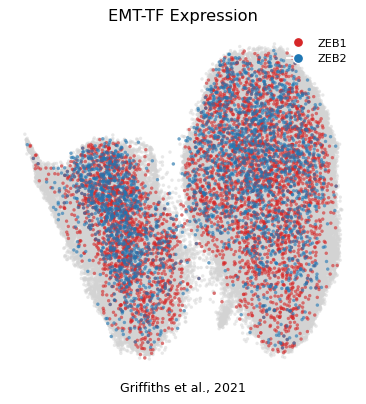

In [1]:
fig,ax=plt.subplots(1,1,figsize=(5,5))
sc.pl.umap(man,size=30,alpha=.5,frameon=False,show=False,ax=ax)
for g,(cl,thr) in gplt.items():
    x=np.asarray(raw[:,g].X.todense()).ravel(); sub=man[x>thr].copy()
    sc.pl.umap(sub,na_color=cl,size=30,alpha=.6,frameon=False,show=False,ax=ax)
ax.invert_yaxis(); ax.invert_xaxis(); ax.set_title('EMT-TF Expression',size=13)
handles=[Line2D([0],[0],marker='o',color='w',markerfacecolor=gplt[g][0],markersize=8,label=g) for g in chosen]
ax.legend(handles=handles,loc='upper right',frameon=False,fontsize=9)
ax.text(.5,-.05,'Griffiths et al., 2021',ha='center',transform=ax.transAxes)
fig.savefig(os.path.join(pth_fig,'expression.pdf'),bbox_inches='tight')
print('saved expression.pdf', chosen)